# Diversificación de portafolios con Monte Carlo

Se construyen tres portafolios con los mismos cuatro activos y distintos pesos, y se simula su valor dentro de un año para comparar riesgo y rendimiento.

**Activos:**

| Activo | Empresa | Moneda |
|---|---|---|
| NVDA | Nvidia | USD |
| BIMBOA.MX | Grupo Bimbo | MXN |
| CEMEXCPO.MX | Cemex | MXN |
| AZN | AstraZeneca | USD |

**Portafolios:**

| Portafolio | Pesos $w$ | Idea |
|---|---|---|
| P1 | [1, 0, 0, 0] | Todo en un solo activo |
| P2 | [0.25, 0.25, 0.25, 0.25] | Pesos iguales |
| P3 | [0.1, 0.2, 0.3, 0.4] | Pesos crecientes |

**Valor inicial:** $V_0 = 100{,}000$ MXN

Dos activos cotizan en dólares y dos en pesos. Para expresar todo en MXN se simula también el tipo de cambio $X_t$ (pesos por dólar).

**Procedimiento:**
1. Descargar los precios de los últimos 3 años, incluyendo el tipo de cambio USD/MXN.
2. Estimar $\mu$, $\sigma$ y la correlación con rendimientos logarítmicos.
3. Simular activos y tipo de cambio a un año ($T = 1$) con $M = 10{,}000$ escenarios.
4. Calcular cuántas acciones se compran de cada activo.
5. Calcular el valor final del portafolio en pesos.

### Librerías

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

## 1. Datos históricos de los últimos 3 años

### Activos, moneda de cada uno y tipo de cambio

In [2]:
activos = {
    "NVDA":        "USD",
    "BIMBOA.MX":   "MXN",
    "CEMEXCPO.MX": "MXN",
    "AZN":         "USD",
}

tickers = list(activos.keys())
fx      = "MXN=X"            # pesos por dólar
todos   = tickers + [fx]

### Descarga de precios de cierre

México y EE.UU. tienen feriados distintos, así que hay días en que un mercado abre y el otro no. Se conservan solo los días con precio para los cinco instrumentos, para que rendimientos y correlaciones se calculen sobre los mismos días.

In [3]:
data = yf.download(todos, start="2023-11-01", end="2026-11-01",
                   auto_adjust=True, progress=False)

precios = data["Close"][todos].dropna()
print(f"Días con datos completos: {len(precios)}")
precios.tail()

Días con datos completos: 727


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Date,,,,,
2026-10-26,216.000000,63.490002,18.990000,172.059998,18.71900
2026-10-27,217.940002,64.849998,19.730000,170.080002,18.55020
2026-10-28,215.380005,61.830002,19.700001,169.509995,18.68704
2026-10-29,213.660004,63.689999,20.480000,174.399994,18.63179
2026-10-30,204.639999,66.180000,20.230000,186.649994,18.85210


### Evolución de los precios (base 100)

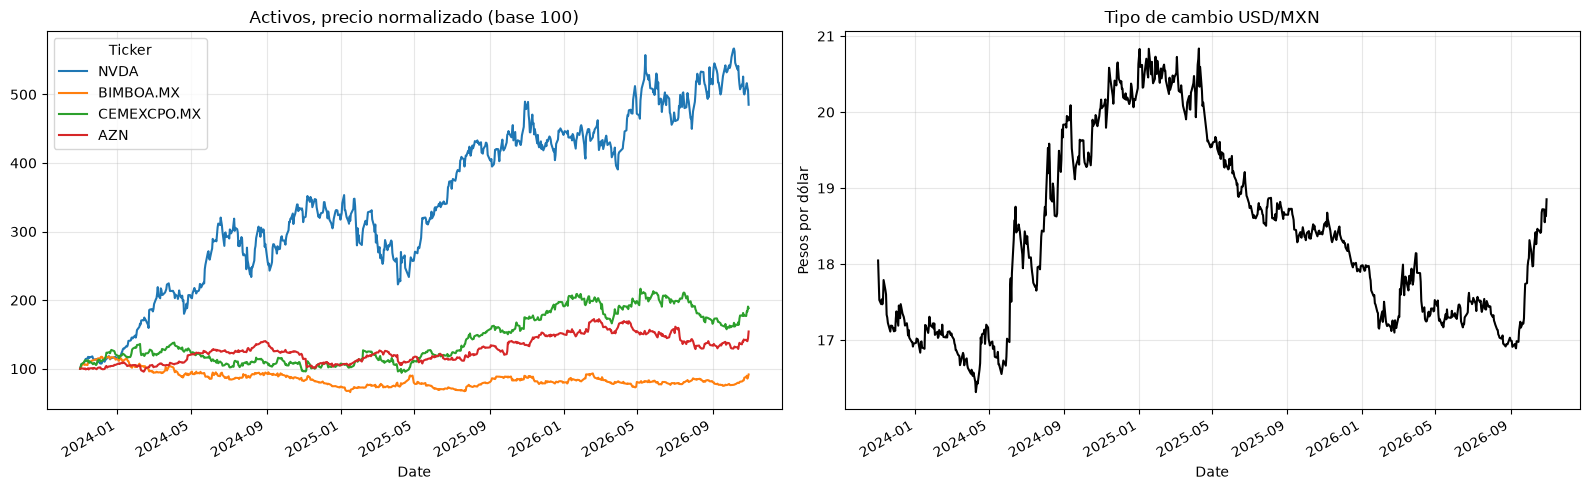

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

(precios[tickers] / precios[tickers].iloc[0] * 100).plot(ax=axes[0], lw=1.5)
axes[0].set_title("Activos, precio normalizado (base 100)")
axes[0].grid(alpha=0.3)

precios[fx].plot(ax=axes[1], color="black", lw=1.5)
axes[1].set_title("Tipo de cambio USD/MXN")
axes[1].set_ylabel("Pesos por dólar")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Estimación de μ, σ y correlación

### Parámetros anualizados

Cada activo se analiza en su propia moneda. El tipo de cambio tiene su propio $\mu$ y $\sigma$, igual que una acción.

In [5]:
log_ret = np.log(precios / precios.shift(1)).dropna()

sigma = log_ret.std() * np.sqrt(252)
mu    = log_ret.mean() * 252 + 0.5 * sigma**2
S0    = precios.iloc[-1]

parametros = pd.DataFrame({
    "Moneda": [activos.get(c, "MXN por USD") for c in todos],
    "S0": S0, "mu": mu, "sigma": sigma
})
parametros.round(4)



,Moneda,S0,mu,sigma
Ticker,,,,
NVDA,USD,204.6400,0.6603,0.4738
BIMBOA.MX,MXN,66.1800,0.0144,0.2995
CEMEXCPO.MX,MXN,20.2300,0.2747,0.3317
AZN,USD,186.6500,0.1822,0.2518
MXN=X,MXN por USD,18.8521,0.0214,0.1114


### Correlación entre activos y tipo de cambio

La última columna muestra cómo se mueve cada activo cuando sube el dólar. Las acciones mexicanas suelen tener correlación negativa con el tipo de cambio: cuando hay aversión al riesgo, el peso se deprecia y la bolsa local baja al mismo tiempo.

In [6]:
correlacion = log_ret.corr()
correlacion.round(3)

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Ticker,,,,,
NVDA,1.000,0.086,0.222,0.015,0.005
BIMBOA.MX,0.086,1.000,0.208,0.111,0.040
CEMEXCPO.MX,0.222,0.208,1.000,0.095,-0.043
AZN,0.015,0.111,0.095,1.000,-0.007
MXN=X,0.005,0.040,-0.043,-0.007,1.000


## 3. Simulación a un año

Los cuatro activos y el tipo de cambio se simulan día por día al mismo tiempo. Para respetar la correlación histórica, los choques aleatorios se transforman con la **descomposición de Cholesky**: si $Z$ son normales independientes, $Z \cdot L^T$ son normales con la correlación deseada.

### Parámetros de simulación

In [7]:
V0 = 100_000
T  = 1
n  = 252
dt = T / n
M  = 10_000

L = np.linalg.cholesky(correlacion.values)
m = mu.values
s = sigma.values
k = len(todos)          # 4 activos + tipo de cambio

### Simulación de activos y tipo de cambio

In [8]:
np.random.seed(42)

S = np.zeros((M, n + 1, k))        # rutas x días x (activos + tipo de cambio)
S[:, 0, :] = S0.values

for t in range(1, n + 1):
    Z = np.random.normal(0, 1, (M, k))
    Z_corr = Z @ L.T
    S[:, t, :] = S[:, t-1, :] * np.exp((m - 0.5*s**2)*dt + s*np.sqrt(dt)*Z_corr)

print(f"Matriz simulada: {S.shape}")

Matriz simulada: (10000, 253, 5)


### Verificación: la correlación simulada coincide con la histórica

In [9]:
rend_sim = np.log(S[:, -1, :] / S[:, 0, :])
pd.DataFrame(np.corrcoef(rend_sim.T), index=todos, columns=todos).round(3)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
NVDA,1.000,0.084,0.220,0.018,0.028
BIMBOA.MX,0.084,1.000,0.197,0.113,0.039
CEMEXCPO.MX,0.220,0.197,1.000,0.106,-0.031
AZN,0.018,0.113,0.106,1.000,0.013
MXN=X,0.028,0.039,-0.031,0.013,1.000


### Tipo de cambio simulado

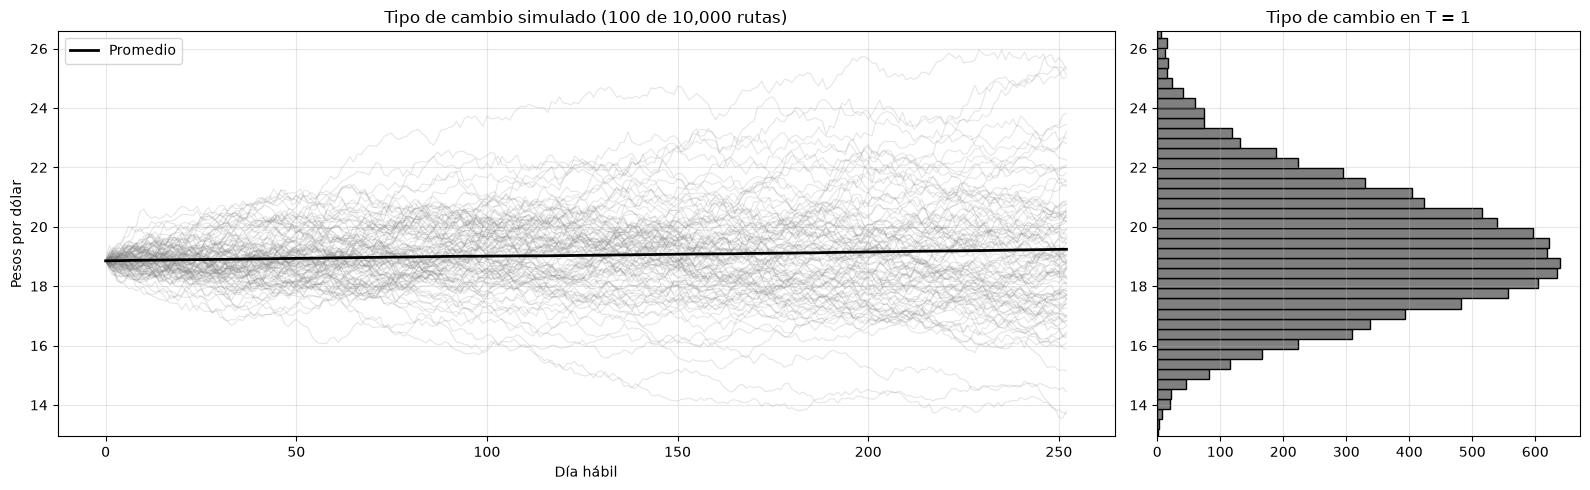

Tipo de cambio hoy  : 18.8521
Esperado en un año  : 19.2414
Rango P5 a P95      : [15.9636, 22.8974]


In [10]:
X = S[:, :, -1]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.5, 1]})

axes[0].plot(X[:100].T, color="gray", alpha=0.2, lw=0.8)
axes[0].plot(X.mean(axis=0), color="black", lw=2, label="Promedio")
axes[0].set_title("Tipo de cambio simulado (100 de 10,000 rutas)")
axes[0].set_xlabel("Día hábil"); axes[0].set_ylabel("Pesos por dólar")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].hist(X[:, -1], bins=50, orientation="horizontal", color="gray", edgecolor="black")
axes[1].set_ylim(axes[0].get_ylim())
axes[1].set_title("Tipo de cambio en T = 1")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tipo de cambio hoy  : {S0[fx]:.4f}")
print(f"Esperado en un año  : {X[:, -1].mean():.4f}")
print(f"Rango P5 a P95      : [{np.percentile(X[:, -1], 5):.4f}, {np.percentile(X[:, -1], 95):.4f}]")

### Precios de los activos expresados en pesos

Los activos en dólares se multiplican por el tipo de cambio de su misma ruta y su mismo día:

$$S^{MXN}_{t,i} = S_{t,i} \cdot X_t \quad \text{si el activo cotiza en USD}$$

Así, el valor en pesos de NVDA y de AZN depende de dos fuentes de riesgo: el precio de la acción y el tipo de cambio.

In [11]:
es_usd = np.array([activos[tk] == "USD" for tk in tickers])

S_mxn = S[:, :, :-1].copy()
S_mxn[:, :, es_usd] = S_mxn[:, :, es_usd] * X[:, :, None]

S0_mxn = S_mxn[0, 0, :]
pd.DataFrame({"Moneda": [activos[tk] for tk in tickers],
              "S0 en su moneda": S0[tickers].values,
              "S0 en MXN": S0_mxn}, index=tickers).round(2)

,Moneda,S0 en su moneda,S0 en MXN
NVDA,USD,204.64,3857.89
BIMBOA.MX,MXN,66.18,66.18
CEMEXCPO.MX,MXN,20.23,20.23
AZN,USD,186.65,3518.74


## 4. Número de acciones por activo

$$N_i = \frac{w_i \, V_0}{S^{MXN}_{0,i}}$$

Para los activos en dólares, el precio inicial se convierte primero a pesos con el tipo de cambio de hoy. Se permiten fracciones de acción para invertir exactamente $V_0$.

### Pesos y acciones de cada portafolio

In [12]:
portafolios = {
    "P1: [1, 0, 0, 0]":             np.array([1, 0, 0, 0]),
    "P2: [0.25, 0.25, 0.25, 0.25]": np.array([0.25, 0.25, 0.25, 0.25]),
    "P3: [0.1, 0.2, 0.3, 0.4]":     np.array([0.1, 0.2, 0.3, 0.4]),
}

acciones = {}
for nombre, w in portafolios.items():
    acciones[nombre] = w * V0 / S0_mxn

pd.DataFrame(acciones, index=tickers).T.round(4)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
"P1: [1, 0, 0, 0]",25.9209,0.0000,0.0000,0.0000
"P2: [0.25, 0.25, 0.25, 0.25]",6.4802,377.7576,1235.7885,7.1048
"P3: [0.1, 0.2, 0.3, 0.4]",2.5921,302.2061,1482.9462,11.3677


### Verificación: cada portafolio invierte exactamente V0

In [13]:
for nombre, N in acciones.items():
    print(f"{nombre:32}  inversión inicial = {np.sum(N * S0_mxn):,.2f} MXN")

P1: [1, 0, 0, 0]                  inversión inicial = 100,000.00 MXN
P2: [0.25, 0.25, 0.25, 0.25]      inversión inicial = 100,000.00 MXN
P3: [0.1, 0.2, 0.3, 0.4]          inversión inicial = 100,000.00 MXN


## 5. Valor final del portafolio en pesos

$$V_t = \sum_{i=1}^{4} N_i \, S^{MXN}_{t,i}$$

### Valor del portafolio en cada día y cada ruta

In [14]:
valor = {}
for nombre, N in acciones.items():
    valor[nombre] = (S_mxn * N).sum(axis=2)      # matriz M x (n+1)

VT = {nombre: V[:, -1] for nombre, V in valor.items()}

### Resumen de resultados

- **Rendimiento esperado:** $E[V_T]/V_0 - 1$
- **Volatilidad:** desviación estándar del rendimiento
- **P(pérdida):** probabilidad de terminar el año por debajo de $V_0$
- **Peor caso (P5) y mejor caso (P95):** percentiles 5 y 95 de $V_T$
- **VaR 95%:** pérdida que no se supera en el 95% de los escenarios, $V_0 - P5$

In [15]:
resumen = []
for nombre, vt in VT.items():
    rend = vt / V0 - 1
    resumen.append({
        "Portafolio": nombre,
        "E[V_T]": vt.mean(),
        "Rend. esperado (%)": rend.mean() * 100,
        "Volatilidad (%)": rend.std(ddof=1) * 100,
        "P(pérdida) (%)": (vt < V0).mean() * 100,
        "Peor caso P5": np.percentile(vt, 5),
        "Mejor caso P95": np.percentile(vt, 95),
        "VaR 95%": V0 - np.percentile(vt, 5),
    })

tabla_resumen = pd.DataFrame(resumen)
tabla_resumen.round(2)

,Portafolio,E[V_T],Rend. esperado (%),Volatilidad (%),P(pérdida) (%),Peor caso P5,Mejor caso P95,VaR 95%
0,"P1: [1, 0, 0, 0]",196877.09,96.88,102.15,12.74,77542.49,389754.45,22457.51
1,"P2: [0.25, 0.25, 0.25, 0.25]",138089.41,38.09,34.22,10.52,92123.55,200311.40,7876.45
2,"P3: [0.1, 0.2, 0.3, 0.4]",128447.75,28.45,26.36,13.12,90525.28,175363.37,9474.72


### Trayectorias del valor de cada portafolio

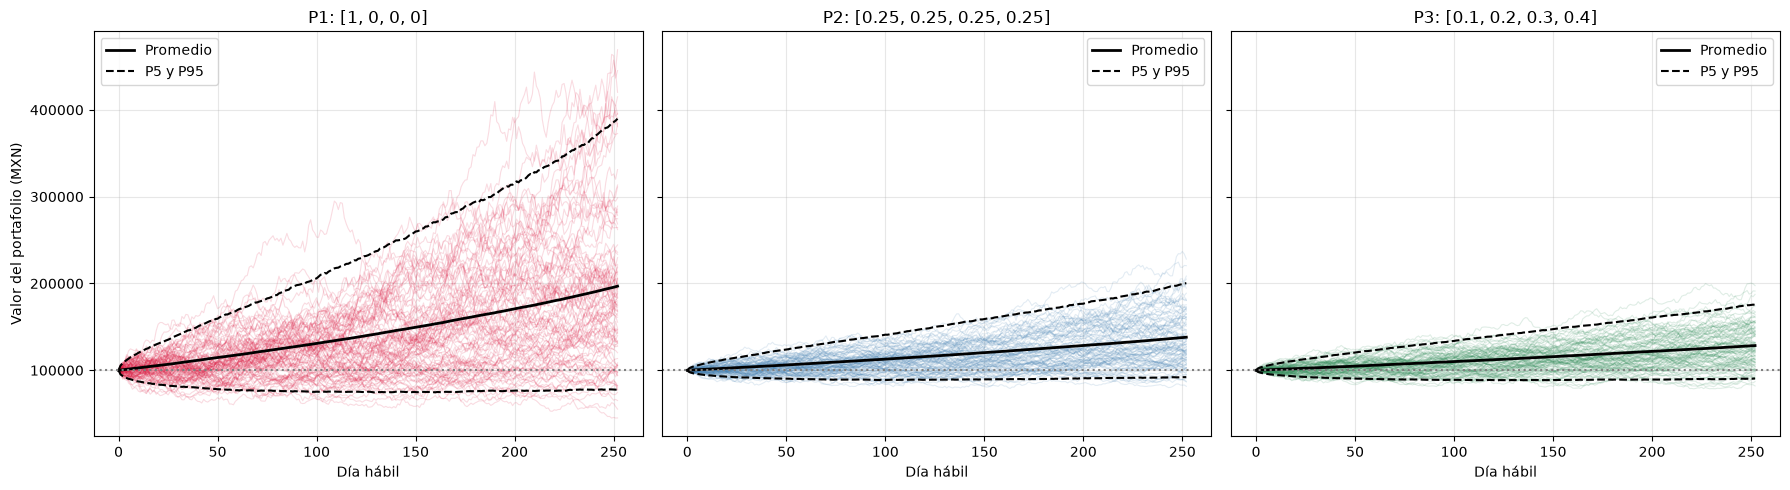

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
colores = ["crimson", "steelblue", "seagreen"]

for ax, (nombre, V), color in zip(axes, valor.items(), colores):
    ax.plot(V[:100].T, color=color, alpha=0.15, lw=0.8)
    ax.plot(V.mean(axis=0), color="black", lw=2, label="Promedio")
    ax.plot(np.percentile(V, 5, axis=0),  color="black", ls="--", lw=1.5, label="P5 y P95")
    ax.plot(np.percentile(V, 95, axis=0), color="black", ls="--", lw=1.5)
    ax.axhline(V0, color="gray", ls=":", lw=1.5)
    ax.set_title(nombre)
    ax.set_xlabel("Día hábil")
    ax.legend(); ax.grid(alpha=0.3)

axes[0].set_ylabel("Valor del portafolio (MXN)")
plt.tight_layout()
plt.show()

### Distribución del valor final

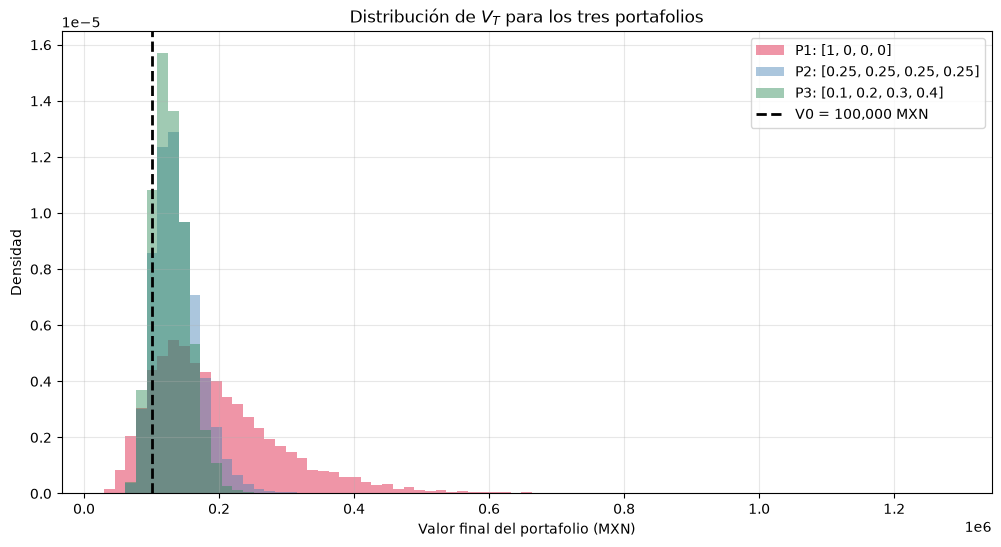

In [17]:
plt.figure(figsize=(12, 6))
bins = np.linspace(min(v.min() for v in VT.values()), max(v.max() for v in VT.values()), 80)

for (nombre, vt), color in zip(VT.items(), colores):
    plt.hist(vt, bins=bins, alpha=0.45, color=color, label=nombre, density=True)

plt.axvline(V0, color="black", ls="--", lw=2, label="V0 = 100,000 MXN")
plt.xlabel("Valor final del portafolio (MXN)")
plt.ylabel("Densidad")
plt.title("Distribución de $V_T$ para los tres portafolios")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Riesgo contra rendimiento

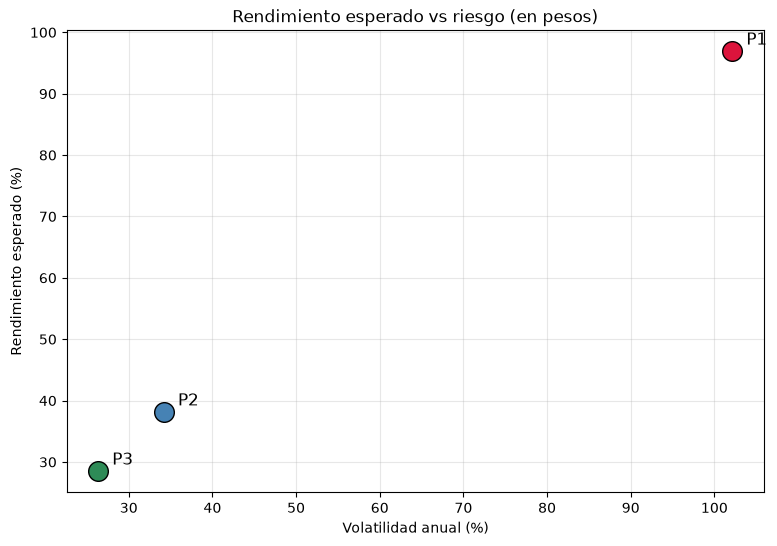

In [18]:
plt.figure(figsize=(9, 6))
for (_, fila), color in zip(tabla_resumen.iterrows(), colores):
    plt.scatter(fila["Volatilidad (%)"], fila["Rend. esperado (%)"], s=200,
                color=color, edgecolor="black", zorder=3)
    plt.annotate(fila["Portafolio"].split(":")[0],
                 (fila["Volatilidad (%)"], fila["Rend. esperado (%)"]),
                 textcoords="offset points", xytext=(10, 5), fontsize=12)

plt.xlabel("Volatilidad anual (%)")
plt.ylabel("Rendimiento esperado (%)")
plt.title("Rendimiento esperado vs riesgo (en pesos)")
plt.grid(alpha=0.3)
plt.show()

In [19]:
rend_usd = S[:, -1, 0] / S[:, 0, 0] - 1
rend_mxn = S_mxn[:, -1, 0] / S_mxn[:, 0, 0] - 1

print(f"NVDA en dólares : rend. esperado {rend_usd.mean()*100:6.2f}%   volatilidad {rend_usd.std(ddof=1)*100:6.2f}%")
print(f"NVDA en pesos   : rend. esperado {rend_mxn.mean()*100:6.2f}%   volatilidad {rend_mxn.std(ddof=1)*100:6.2f}%")

NVDA en dólares : rend. esperado  92.61%   volatilidad  96.33%
NVDA en pesos   : rend. esperado  96.88%   volatilidad 102.15%
